## 1. Setup & configuration

In [5]:
%pip install faiss-gpu

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 135.3/135.3 MB 14.5 MB/s eta 0:00:0000:0100:01
Note: you may need to restart the kernel to use updated packages.


In [6]:
import json
import re
import time
import platform
from dataclasses import dataclass
from pathlib import Path

import faiss
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pymupdf
import torch
import transformers
import sentence_transformers
from sentence_transformers import CrossEncoder, SentenceTransformer
from transformers import AutoModelForCausalLM, AutoTokenizer

# ---- configuration (everything tunable lives here) ----
PDF_PATH = Path("/kaggle/input/datasets/patelpriyanshu54/lma-dataset-pdf/cfpb_loan_originator_small_entity_compliance_guide.pdf")
RESULTS_DIR = Path("/kaggle/working/results")
FIG_DIR = Path("/kaggle/working/figures")
BI_ENCODER_NAME = "sentence-transformers/all-MiniLM-L6-v2"   # dense Bi-Encoder, 384-dim
CROSS_ENCODER_NAME = "cross-encoder/ms-marco-MiniLM-L-6-v2"  # re-ranker suggested by the brief
LLM_NAME = "Qwen/Qwen2.5-3B-Instruct"                        # local open-weights generator
TOP_K = 10            # candidates from the first stage
TOP_N = 3             # chunks passed to the LLM
MAX_CHUNK_CHARS = 850  # keeps every chunk under the Bi-Encoder's 256-token window (re-checked in Section 5)
MAX_NEW_TOKENS = 200
SEED = 0

RESULTS_DIR.mkdir(exist_ok=True)
FIG_DIR.mkdir(exist_ok=True)
torch.manual_seed(SEED)
np.random.seed(SEED)
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 200)

assert PDF_PATH.exists(), f"Put the CFPB guide PDF at {PDF_PATH} first."
print(f"python {platform.python_version()} | torch {torch.__version__} | transformers {transformers.__version__} "
      f"| sentence-transformers {sentence_transformers.__version__} | faiss {faiss.__version__}")
print(f"CPU: {platform.processor() or platform.machine()} | torch threads: {torch.get_num_threads()} | CUDA: {torch.cuda.is_available()}")

python 3.13.15 | torch 2.11.0+cu128 | transformers 5.16.1 | sentence-transformers 5.7.0 | faiss 1.15.1
CPU: x86_64 | torch threads: 2 | CUDA: True


In [8]:
# Plot style shared by every figure: thin marks, recessive grid, text in neutral ink.
# Colour = pipeline identity, fixed for the whole notebook (blue = baseline, orange = re-ranked).
C_BASE, C_RERANK = "#2a78d6", "#eb6834"
INK, INK_2, GRID = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
    "axes.edgecolor": GRID, "axes.labelcolor": INK_2, "axes.titlecolor": INK,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "xtick.color": INK_2, "ytick.color": INK_2, "font.size": 9.5, "axes.titlesize": 11,
    "legend.frameon": False, "axes.axisbelow": True,
})

## 2. Load the PDF and clean it

In [9]:
MIN_TEXT_PT = 9.0     # body text is 11 pt, sidebar call-outs 10 pt; page numbers (8 pt), footnotes and footnote markers (7 pt) are dropped
SIDEBAR_X = 300       # call-out boxes sit in the right-hand column (x > 300 pt)
H3_PT = 16            # run-in labels such as "Profits-based compensation plans"
GAP_NEW_PARA = 22     # line pitch is ~17.5 pt; a vertical gap > 22 pt starts a new paragraph
TERMINAL = tuple(".!?:;)\u201d\"")


def _line_records(path):
    # One record per text line with its page, font size, position and a kind (h1 / h2 / h3 / body / side / bullet_mark).
    recs = []
    with pymupdf.open(path) as doc:
        n_pages = len(doc)
        for pno, page in enumerate(doc, start=1):
            for block in page.get_text("dict")["blocks"]:
                for line in block.get("lines", []):
                    spans = [sp for sp in line["spans"] if sp["size"] >= MIN_TEXT_PT or "Wingdings" in sp["font"]]
                    if not spans:
                        continue
                    text = "".join(sp["text"] for sp in spans if "Wingdings" not in sp["font"]).strip()
                    if not text:
                        if any("Wingdings" in sp["font"] for sp in spans):     # a bullet glyph on its own
                            recs.append({"page": pno, "kind": "bullet_mark", "y": line["bbox"][1], "x": line["bbox"][0], "text": ""})
                        continue
                    sp0 = [sp for sp in spans if "Wingdings" not in sp["font"]][0]
                    size, x, y = round(sp0["size"]), line["bbox"][0], line["bbox"][1]
                    if size >= 30:
                        kind = "h1"                                   # section title (32 pt)
                    elif 20 <= size <= 24:
                        kind = "h2"                                   # question heading (22 pt)
                    elif size == H3_PT:
                        kind = "h3"
                    elif x >= SIDEBAR_X and size <= 10:
                        kind = "side"                                 # call-out box in the right-hand column
                    elif "Bold" in sp0["font"] and size <= 10:
                        kind = "h3"                                   # small bold labels, e.g. "Compensation", "Initial review and assessment"
                    else:
                        kind = "body"
                    recs.append({"page": pno, "kind": kind, "y": y, "x": x, "text": text, "font": sp0["font"], "size": size})
    return recs, n_pages


def _join(a, b):
    # Join two hard-wrapped lines; no space after a trailing hyphen ("tax-" + "advantaged").
    return a + b if a.endswith("-") else f"{a} {b}"


def _is_complete_heading(text, nxt):
    # A (possibly multi-line) heading is complete once it ends with "?" or ")" with balanced parentheses,
    # unless the next line is a "(citation)" continuation of a question.
    if text.count("(") > text.count(")"):
        return False
    return text.rstrip().endswith(("?", ")")) and not nxt.startswith("(")


def _appendix_elements(rows, pno):
    # Appendix A is a 4-column chart: rebuild one paragraph per column ("Employee hired ...: Required: ...").
    elems = [{"kind": "h1", "text": "Appendix A - Required Background Information and Qualification Determinations",
              "page": pno, "y0": 0, "bullet": False}]
    rows = [r for r in rows if r["kind"] != "bullet_mark"]
    cur, prev_y = None, None
    for r in sorted((r for r in rows if r["kind"] == "body" and "Georgia" in r["font"]), key=lambda r: r["y"]):
        if prev_y is None or r["y"] - prev_y > GAP_NEW_PARA:
            cur = {"kind": "para", "text": r["text"], "page": pno, "y0": r["y"], "bullet": False}
            elems.append(cur)
        else:
            cur["text"] = _join(cur["text"], r["text"])
        prev_y = r["y"]
    table = [r for r in rows if r["kind"] in ("body", "h3") and "Georgia" not in r["font"] and r["size"] in (11, 12)]
    cols = {}
    for r in table:
        c = 0 if r["x"] < 185 else 1 if r["x"] < 315 else 2 if r["x"] < 445 else 3
        cols.setdefault(c, []).append(r)
    for c in sorted(cols):
        head = " ".join(r["text"] for r in sorted(cols[c], key=lambda r: r["y"]) if r["size"] == 12)
        body, prev_y = [], None
        for r in sorted((r for r in cols[c] if r["size"] == 11), key=lambda r: r["y"]):
            if prev_y is None or r["y"] - prev_y > 20:
                body.append(r["text"])
            else:
                body[-1] = _join(body[-1], r["text"])
            prev_y = r["y"]
        elems.append({"kind": "para", "page": pno, "y0": 400 + c, "bullet": False,
                      "text": f"Employee {head[0].lower() + head[1:]}: " + " ".join(body)})
    return elems


def build_stream(recs):
    # Turn line records into an ordered stream of headings and paragraphs.
    # Each element: {"kind": "h1" | "h2" | "h3" | "para" | "side", "text", "page", "y0", "bullet"}.
    appendix_pages = {r["page"] for r in recs if r["kind"] == "h1" and r["text"].strip() == "Appendix A"}
    stream, last_main, last_side = [], None, None
    for pno in sorted({r["page"] for r in recs}):
        rows = [r for r in recs if r["page"] == pno]
        if pno in appendix_pages:
            stream.extend(_appendix_elements(rows, pno))
            last_main = last_side = None
            continue
        main = sorted((r for r in rows if r["kind"] != "side"),
                      key=lambda r: r["y"] - 4 if r["kind"] == "bullet_mark" else r["y"])   # a bullet glyph precedes its text line
        side = sorted((r for r in rows if r["kind"] == "side"), key=lambda r: r["y"])
        page_elems, pending_bullet, prev_y, prev_kind = [], False, None, None
        for r in main:
            k = r["kind"]
            if k == "bullet_mark":
                pending_bullet = True
                continue
            if k in ("h1", "h2", "h3"):
                gap_ok = prev_y is not None and r["y"] - prev_y <= (45 if k == "h1" else 30 if k == "h2" else 26)
                same_kind = last_main is not None and last_main["kind"] == k
                if same_kind and last_main["page"] == pno and k != "h2" and gap_ok \
                        and not (k == "h3" and last_main["text"].endswith(".")):
                    last_main["text"] = _join(last_main["text"], r["text"])
                elif same_kind and k == "h2" and not _is_complete_heading(last_main["text"], r["text"]):
                    last_main["text"] = _join(last_main["text"], r["text"])      # a question heading may continue across a page break
                else:
                    last_main = {"kind": k, "text": r["text"], "page": pno, "y0": r["y"], "bullet": False}
                    page_elems.append(last_main)
                prev_y, prev_kind, pending_bullet = r["y"], k, False
                continue
            # ---- body line
            new_para = (pending_bullet or last_main is None or last_main["kind"] != "para"
                        or (prev_kind != "body" and prev_y is not None)
                        or (prev_y is not None and r["y"] - prev_y > GAP_NEW_PARA))
            if prev_y is None and last_main is not None and last_main["kind"] == "para":
                # first body line on a page: continue the previous page's paragraph if it was cut mid-sentence
                new_para = last_main["text"].endswith(TERMINAL) and not r["text"][:1].islower()
            if new_para:
                last_main = {"kind": "para", "text": r["text"], "page": pno, "y0": r["y"], "bullet": pending_bullet}
                page_elems.append(last_main)
            else:
                last_main["text"] = _join(last_main["text"], r["text"])
            pending_bullet, prev_y, prev_kind = False, r["y"], "body"
        # ---- sidebar call-outs: one paragraph per contiguous block of right-column lines
        sides, prev_y = [], None
        for r in side:
            if prev_y is None and last_side is not None and (not last_side["text"].endswith(TERMINAL) or r["text"][:1].islower()):
                last_side["text"] = _join(last_side["text"], r["text"])           # call-out continued from the previous page
            elif prev_y is None or r["y"] - prev_y > 20:
                last_side = {"kind": "side", "text": r["text"], "page": pno, "y0": r["y"], "bullet": False}
                sides.append(last_side)
            else:
                last_side["text"] = _join(last_side["text"], r["text"])
            prev_y = r["y"]
        for s in sides:                       # a call-out is placed after the main-column paragraph it sits next to
            pos = next((i for i, e in enumerate(page_elems) if e["y0"] > s["y0"]), len(page_elems))
            page_elems.insert(pos, s)
        stream.extend(page_elems)
    return stream


def load_pdf_stream(path):
    recs, n_pages = _line_records(path)
    first = min(r["page"] for r in recs if r["kind"] == "h1" and r["text"].startswith("Introduction"))
    return build_stream([r for r in recs if r["page"] >= first]), n_pages, first   # skip cover, version log, table of contents


stream, n_pages, first_page = load_pdf_stream(PDF_PATH)
kinds = pd.Series([e["kind"] for e in stream]).value_counts()
print(f"{n_pages} pages (body starts on p.{first_page}) -> {len(stream)} elements: {kinds.get('h1', 0)} section titles, "
      f"{kinds.get('h2', 0)} question headings, {kinds.get('para', 0)} paragraphs, {kinds.get('side', 0)} call-outs; "
      f"{sum(len(e['text']) for e in stream):,} characters")
for e in stream[:7]:
    print(f"  [{e['kind']:<4} p.{e['page']}] {e['text'][:105]}")

89 pages (body starts on p.10) -> 681 elements: 18 section titles, 59 question headings, 555 paragraphs, 22 call-outs; 129,804 characters
  [h1   p.10] Introduction
  [para p.10] In the aftermath of the mortgage crisis, regulators and lawmakers began focusing on the influential role 
  [para p.10] Since the mortgage crisis, regulators and lawmakers have imposed a number of requirements concerning loan
  [para p.10] The Bureau of Consumer Financial Protection (the Bureau) issued regulations to implement the Dodd-Frank A
  [para p.10] The 2013 Loan Originator Rule expanded upon and clarified earlier regulations adopted by the Board of Gov
  [h3   p.10] Loan originator definition
  [para p.10] Clarified the definition of “loan originator,” including exclusions for certain employees of manufactured


## 3. Parse the document structure

In [10]:
@dataclass
class Section:
    sec: str        # "1".."16", or "A" for Appendix A
    sub: int        # 0 = text before the first question of the section, otherwise 1, 2, ... (same numbering as the guide's own "Section 8.6")
    sec_title: str
    title: str      # the question heading (or the section title when sub == 0)
    paras: list     # [(page, text), ...]


def split_sections(stream):
    sections, n, skip, cur, label, sec_title = [], 0, False, None, None, None
    for e in stream:
        k = e["kind"]
        if k == "h1":
            if e["text"].startswith("Additional Resources"):
                skip, cur = True, None                       # URL boilerplate, not part of the rule summary
                continue
            skip = False
            if e["text"].startswith("Appendix A"):
                label = "A"
            else:
                n += 1
                label = str(n)
            sec_title = e["text"]
            cur = Section(label, 0, sec_title, sec_title, [])
            sections.append(cur)
        elif skip or cur is None:
            continue
        elif k == "h2":
            cur = Section(label, cur.sub + 1, sec_title, e["text"], [])
            sections.append(cur)
        elif k == "h3":
            cur.paras.append((e["page"], "@@LABEL@@" + e["text"]))
        else:                                                # para / side
            cur.paras.append((e["page"], ("- " if e["bullet"] else "") + e["text"]))
    # glue each small bold label ("Compensation", "Initial review and assessment") onto the paragraph that follows it
    for s in sections:
        out, label_txt = [], None
        for pg, t in s.paras:
            if t.startswith("@@LABEL@@"):
                label_txt = t[9:] if label_txt is None else f"{label_txt} {t[9:]}"
            else:
                out.append((pg, f"{label_txt}: {t}" if label_txt else t))
                label_txt = None
        if label_txt:
            out.append((s.paras[-1][0], label_txt))
        s.paras = out
    return [s for s in sections if s.paras]


sections = split_sections(stream)
assert sorted({int(s.sec) for s in sections if s.sec != "A"}) == list(range(1, 17)), "expected numbered sections 1..16"
assert sections[-1].sec == "A", "expected Appendix A last"
# sanity check against the guide's own cross-references ("... in Section 8.6", "... in Section 4.3")
assert next(s for s in sections if (s.sec, s.sub) == ("8", 6)).title.startswith("How may the payments from a non-deferred")
assert next(s for s in sections if (s.sec, s.sub) == ("4", 3)).title.startswith("Does compensation include fees")
n_q = sum(s.sub > 0 for s in sections)
print(f"16 numbered sections + Appendix A -> {len(sections)} sections ({n_q} question headings, "
      f"{len(sections) - n_q - 1} section-level intros)")
s86 = next(s for s in sections if (s.sec, s.sub) == ("8", 6))
print(f"\nSection 8.{s86.sub} - {s86.title}")
for pg, t in s86.paras[:3]:
    print(f"  [p.{pg}] {t[:230]}")

16 numbered sections + Appendix A -> 66 sections (59 question headings, 6 section-level intros)

Section 8.6 - How may the payments from a non-deferred profits-based compensation plan be structured?
  [p.52] Under a non-deferred profits-based compensation plan, if you are paying the individual loan originator, you may, for example:
  [p.52] - Pay the originator directly in cash, stock, or other non-deferred compensation. (Comment 36(d)(1)-3.ii)
  [p.52] - Use a fixed formula for the amount and distribution of pay.


## 4. Chunking

In [11]:
def _split_long(text, max_chars):
    # Split an over-long paragraph on sentence / list-item boundaries and pack the pieces greedily.
    pieces = re.split(r"(?<=[.;:])\s+(?=\(?[A-Z(])", text)
    out, cur = [], ""
    for p in pieces:
        if cur and len(cur) + 1 + len(p) > max_chars:
            out.append(cur)
            cur = p
        else:
            cur = f"{cur} {p}".strip()
    if cur:
        out.append(cur)
    return out


def chunk_sections(sections, max_chars=MAX_CHUNK_CHARS):
    raw = []                                                  # (section, pages, body) before the part numbers are known
    for sec in sections:
        pieces = [(pg, part) for pg, txt in sec.paras for part in _split_long(txt, max_chars)]
        buf, pgs = "", []
        for pg, txt in pieces:
            if buf and len(buf) + 1 + len(txt) > max_chars:
                raw.append((sec, pgs, buf))
                buf, pgs = "", []
            buf = f"{buf}\n{txt}".strip()
            if pg not in pgs:
                pgs.append(pg)
        if buf:
            raw.append((sec, pgs, buf))
    n_parts = {}
    for sec, _, _ in raw:
        n_parts[(sec.sec, sec.sub)] = n_parts.get((sec.sec, sec.sub), 0) + 1
    chunks, seen = [], {}
    for sec, pgs, body in raw:
        key = (sec.sec, sec.sub)
        seen[key] = seen.get(key, 0) + 1
        if sec.sec == "A":
            base, header = "Appendix A", sec.title
        elif sec.sub == 0:
            base, header = f"Sec. {sec.sec}", f"Section {sec.sec}: {sec.title}"
        else:
            base, header = f"Sec. {sec.sec}.{sec.sub}", f"Section {sec.sec}.{sec.sub}: {sec.title}"
        ref = base if n_parts[key] == 1 else f"{base} ({seen[key]}/{n_parts[key]})"
        chunks.append({"chunk_id": len(chunks), "ref": ref, "section": base, "sec": sec.sec, "sub": sec.sub,
                       "title": sec.title, "pages": str(pgs[0]) if len(pgs) == 1 else f"{pgs[0]}-{pgs[-1]}",
                       "text": f"{header}\n{body}"})
    return chunks


chunks = chunk_sections(sections)
chunk_df = pd.DataFrame(chunks)
chunk_texts = chunk_df["text"].tolist()
chunk_df["n_chars"] = chunk_df["text"].str.len()
print(f"{len(chunks)} chunks from {len(sections)} sections ({chunk_df.section.nunique()} distinct section refs)")
chunk_df["n_chars"].describe().round(0).to_frame("characters per chunk").T

198 chunks from 66 sections (66 distinct section refs)


,count,mean,std,min,25%,50%,75%,max
characters per chunk,198.0,720.0,186.0,302.0,589.0,753.0,856.0,1057.0


In [12]:
# Example: the chunks of Section 9.4 (can an origination charge be paid partly by the consumer and partly by the creditor?)
for _, row in chunk_df[chunk_df.section == "Sec. 9.4"].iterrows():
    print(f"--- chunk {row.chunk_id} | {row.ref} | p. {row.pages}\n{row.text}\n")

--- chunk 136 | Sec. 9.4 (1/3) | p. 61
Section 9.4: Can an origination charge be paid partly by the consumer and partly by the creditor? (Comment 36(d)(2)(i)-2.i and .ii)
No. If you are a loan originator organization and you charge an origination point or fee, the entire amount of the point or fee must be paid entirely by the consumer or entirely out of funds paid by the creditor, such as those generated from a higher interest rate.
For example, assume you are a loan originator organization. You charge a $1,000 origination fee. That fee is the only compensation you are receiving in the transaction and it is not based on transaction terms or a proxy for transaction terms.
The transaction has additional closing costs of $750. The consumer pays $800 at closing toward closing costs, and receives funds from the creditor of $950 generated through a higher interest rate.

--- chunk 137 | Sec. 9.4 (2/3) | p. 61
Section 9.4: Can an origination charge be paid partly by the consumer and partly by

## 5. Pipeline 1 - Bi-Encoder index and baseline retrieval

In [13]:
bi_encoder = SentenceTransformer(BI_ENCODER_NAME, device="cpu")

# make sure no chunk is truncated by the Bi-Encoder's 256 word-piece window
n_tokens = [len(bi_encoder.tokenizer(t)["input_ids"]) for t in chunk_texts]
print(f"Bi-Encoder max_seq_length={bi_encoder.max_seq_length}; chunk tokens: median {int(np.median(n_tokens))}, "
      f"max {max(n_tokens)}, truncated: {sum(n > bi_encoder.max_seq_length for n in n_tokens)}")

t0 = time.perf_counter()
chunk_emb = bi_encoder.encode(chunk_texts, batch_size=32, normalize_embeddings=True,
                              convert_to_numpy=True, show_progress_bar=False).astype(np.float32)
index_time = time.perf_counter() - t0

index = faiss.IndexFlatIP(chunk_emb.shape[1])
index.add(chunk_emb)
print(f"Indexed {index.ntotal} chunks x {chunk_emb.shape[1]} dims in {index_time:.1f}s (one-off, offline cost)")

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

...

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Bi-Encoder max_seq_length=256; chunk tokens: median 159, max 245, truncated: 0
Indexed 198 chunks x 384 dims in 8.0s (one-off, offline cost)


In [14]:
def baseline_retrieve(query, k=TOP_K):
    # Stage 1: embed the query, return the top-k chunk ids and their cosine similarities.
    q = bi_encoder.encode([query], normalize_embeddings=True, convert_to_numpy=True,
                          show_progress_bar=False).astype(np.float32)
    sims, ids = index.search(q, k)
    return ids[0].tolist(), sims[0].tolist()

## 6. Pipeline 2 - Cross-Encoder re-ranking

In [15]:
cross_encoder = CrossEncoder(CROSS_ENCODER_NAME, device="cpu")
print(f"Cross-Encoder max_seq_length={cross_encoder.max_seq_length}")


def rerank(query, candidate_ids):
    # Stage 2: score every (query, chunk) pair jointly and sort descending by Cross-Encoder score.
    scores = cross_encoder.predict([(query, chunk_texts[i]) for i in candidate_ids], show_progress_bar=False)
    order = np.argsort(-scores)
    return [candidate_ids[j] for j in order], scores[order].tolist()

config.json:   0%|          | 0.00/794 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 90.9MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/1.33k [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/711k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/132 [00:00<?, ?B/s]

Cross-Encoder max_seq_length=512


## 7. LLM generation with one shared prompt

In [16]:
llm_tokenizer = AutoTokenizer.from_pretrained(LLM_NAME)
llm = AutoModelForCausalLM.from_pretrained(LLM_NAME, dtype=torch.float32)
llm.eval()

SYSTEM_PROMPT = (
    "You are a careful compliance assistant answering questions about the CFPB's Loan Originator Rule "
    "(Regulation Z, 12 CFR 1026.36) as summarised in the Bureau's small entity compliance guide. "
    "Answer ONLY from the numbered context passages. State the exact figures, conditions and exceptions they contain "
    "and cite the passage reference in brackets exactly as shown, e.g. [Sec. 9.5]. If the passages do not contain the answer, reply: "
    "\"The provided context does not answer this question.\" Keep the answer under 120 words."
)


def build_prompt(query, context_ids):
    context = "\n\n".join(f"[{chunk_df.ref[i]}]\n{chunk_texts[i]}" for i in context_ids)
    return [{"role": "system", "content": SYSTEM_PROMPT},
            {"role": "user", "content": f"Context passages:\n\n{context}\n\nQuestion: {query}"}]


@torch.inference_mode()
def generate_answer(query, context_ids):
    messages = build_prompt(query, context_ids)
    inputs = llm_tokenizer.apply_chat_template(messages, add_generation_prompt=True,
                                               return_tensors="pt", return_dict=True)
    t0 = time.perf_counter()
    out = llm.generate(**inputs, max_new_tokens=MAX_NEW_TOKENS, do_sample=False,
                       pad_token_id=llm_tokenizer.eos_token_id)
    elapsed = time.perf_counter() - t0
    new_tokens = out[0, inputs["input_ids"].shape[1]:]
    return {"answer": llm_tokenizer.decode(new_tokens, skip_special_tokens=True).strip(),
            "gen_s": elapsed, "prompt_tokens": int(inputs["input_ids"].shape[1]),
            "new_tokens": int(len(new_tokens))}

config.json:   0%|          | 0.00/661 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

model.safetensors.index.json:   0%|          | 0.00/35.6k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/434 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

In [17]:
def run_both_pipelines(query, generate=True):
    # Run Pipeline 1 and Pipeline 2 for one query; returns ranks, scores, timings and both answers.
    t0 = time.perf_counter()
    base_ids, base_sims = baseline_retrieve(query)          # shared Stage 1 (top-10)
    t1 = time.perf_counter()
    rr_ids, rr_scores = rerank(query, base_ids)             # Stage 2 (Pipeline 2 only)
    t2 = time.perf_counter()
    res = {"query": query, "base_ids": base_ids, "base_sims": base_sims, "rr_ids": rr_ids, "rr_scores": rr_scores,
           "retrieval_ms": (t1 - t0) * 1e3, "rerank_ms": (t2 - t1) * 1e3}
    if generate:
        res["p1"] = generate_answer(query, base_ids[:TOP_N])   # Answer 1: top-3 by cosine
        res["p2"] = generate_answer(query, rr_ids[:TOP_N])     # Answer 2: top-3 after re-ranking
    return res


demo = run_both_pipelines("What is the 10-percent total compensation limit for a profit-based bonus?")
print("Pipeline 1 top-3:", [chunk_df.ref[i] for i in demo["base_ids"][:3]])
print("Pipeline 2 top-3:", [chunk_df.ref[i] for i in demo["rr_ids"][:3]])
print(f"\nAnswer 1 ({demo['p1']['gen_s']:.1f}s):\n{demo['p1']['answer']}\n\nAnswer 2 ({demo['p2']['gen_s']:.1f}s):\n{demo['p2']['answer']}")

Pipeline 1 top-3: ['Sec. 8.7 (8/12)', 'Sec. 8.7 (4/12)', 'Sec. 8.7 (9/12)']
Pipeline 2 top-3: ['Sec. 8.7 (8/12)', 'Sec. 8.7 (9/12)', 'Sec. 8.7 (7/12)']

Answer 1 (43.6s):
The 10-percent total compensation limit for a profit-based bonus is $2,250 for each quarter, which sums up to $9,000 annually. [Sec. 8.7 (8/12)]

Answer 2 (50.6s):
The 10-percent total compensation limit for a profit-based bonus is $2,250 per quarter or $10,000 annually. [Sec. 8.7 (8/12)] & [Sec. 8.7 (9/12)]


For an easy, well-phrased question both pipelines usually retrieve the same section and give the same answer. The interesting cases are below.

## 8. Failure-mode analysis (stress tests)

In [18]:
STRESS_QUERIES = [
    {"id": "Q1", "category": "Keyword trap / distractor",
     "query": "How long do I need to keep my loan originator compensation records?",
     "gold": ["must keep records related to the Loan Originator Rule’s requirements for three years"],
     "expected": "Sec. 11.2: three years after the date of payment or receipt of compensation - counted separately for each "
                 "payment, even if several payments relate to one transaction (a payment on June 5, 2014 is kept through June 4, "
                 "2017). Trap: Sec. 11.1 is literally titled 'What records must be maintained' but lists the records, not the "
                 "retention period."},
    {"id": "Q2", "category": "Exception / corner case",
     "query": "If the borrower pays the brokerage firm directly, can the firm still pay its loan officer a commission on that loan?",
     "gold": ["you may still pay compensation to the individual loan originator for the transaction"],
     "expected": "Sec. 9.5: yes. An organization paid directly by the consumer may still pay its individual loan originator a "
                 "commission, but neither of them may receive compensation from the creditor on that transaction, and the "
                 "commission may be based only on the compensation the organization received, not on any other transaction term. "
                 "Trap: Sec. 9.1 says an originator may not be paid by both the consumer and another person."},
    {"id": "Q3", "category": "Exception / corner case",
     "query": "Can a loan originator cut their own commission to help the borrower with a closing cost that came in higher than expected?",
     "gold": ["you may decrease your compensation to lower the actual settlement cost for a consumer"],
     "expected": "Sec. 5.8: yes, but only in narrow circumstances - if an actual settlement cost rose unforeseeably above the "
                 "estimate disclosed to the consumer, the originator may decrease its compensation to cover it (example: a rate- "
                 "lock extension fee after a title problem). Trap: Sec. 5.7 says an originator generally may not lower its "
                 "compensation selectively (e.g. to match a competitor's rate)."},
    {"id": "Q4", "category": "Negation / role constraint",
     "query": "Is a licensed real estate agent a loan originator if they only help with the home sale?",
     "gold": ["A properly licensed real estate broker that performs only real estate brokerage activities"],
     "expected": "Sec. 3.2: no - a properly licensed real estate broker that performs only real estate brokerage activities is not "
                 "a loan originator, so long as it is not compensated by a loan originator or creditor (payment solely for "
                 "brokerage activities, or for brokerage on property owned by that loan originator or creditor, does not count as "
                 "such compensation). Trap: the neighbouring passages list the activities that DO make someone a loan originator."},
    {"id": "Q5", "category": "Negation / constraint ('unless')",
     "query": "Can a lender require borrowers to settle disputes through arbitration?",
     "gold": ["terms that require arbitration or any other non-judicial procedure"],
     "expected": "Sec. 14.1: no - a creditor may not include terms requiring arbitration or any other non-judicial procedure for a "
                 "closed-end mortgage (or a HELOC on a principal dwelling), EXCEPT that after a dispute arises the consumer, "
                 "creditor or an assignee may agree to arbitration. Traps: Sec. 14.2 (waiver of federal claims) and overview "
                 "passages that mention arbitration in passing."},
    {"id": "Q6", "category": "Buried at rank 4-10",
     "query": "How far back does a felony conviction matter when screening a new loan officer?",
     "gold": ["During the past seven years not been convicted of"],
     "expected": "Sec. 10.6: seven years - the originator must not have been convicted of, or pleaded guilty or nolo contendere "
                 "to, a felony during the past seven years; a felony involving fraud, dishonesty, breach of trust or money "
                 "laundering disqualifies at any time. Expunged or pardoned convictions do not disqualify."},
    {"id": "Q7", "category": "Buried at rank 4-10 / exception",
     "query": "Do independent mortgage brokers have to complete our training program?",
     "gold": ["You are not required to provide training to loan originators who operate under a brokerage agreement"],
     "expected": "Sec. 10.7: no - the training duty covers the organization's own loan originator employees, not loan originators "
                 "who operate under a brokerage agreement (for those, the organization only has to verify licensing/registration)."},
    {"id": "Q8", "category": "Keyword trap / synonym",
     "query": "Can my mortgage sales staff earn more commission on loans that carry a higher interest rate?",
     "gold": ["receiving higher compensation based on the transaction’s interest rate"],
     "expected": "Sec. 5.1: no - paying more commission because the interest rate is higher is compensation based on a transaction "
                 "term (example in the guide: 2 percent of the loan amount if the rate is above 6 percent, 1 percent otherwise). "
                 "Traps: Sec. 5.9 mentions higher rates after a pay rise, Sec. 5.10 says creditors may price loans for risk."},
]


def gold_ids(gold_phrases):
    # A chunk is gold if it contains any of the verbatim gold phrases (case/whitespace-insensitive).
    norm = lambda s: re.sub(r"\s+", " ", s).lower()
    return {i for i, t in enumerate(chunk_texts) if any(norm(g) in norm(t) for g in gold_phrases)}


def rank_of(ids, gold):
    # 1-based rank of the best gold chunk in a ranked list, or None if absent.
    hits = [r + 1 for r, i in enumerate(ids) if i in gold]
    return hits[0] if hits else None


def full_bi_rank(query, gold):
    # Rank of the best gold chunk among ALL chunks under the Bi-Encoder (to see how far down it is).
    q = bi_encoder.encode([query], normalize_embeddings=True, convert_to_numpy=True, show_progress_bar=False)[0]
    sims = chunk_emb @ q
    return min(int((sims > sims[g]).sum()) + 1 for g in gold)


def rank_table(res, gold):
    # Top-10 table: baseline order, cosine, Cross-Encoder score and new rank; marks what each pipeline sends to the LLM.
    ce_score = dict(zip(res["rr_ids"], res["rr_scores"]))
    new_rank = {cid: r + 1 for r, cid in enumerate(res["rr_ids"])}
    rows = []
    for r, (cid, sim) in enumerate(zip(res["base_ids"], res["base_sims"]), start=1):
        rows.append({"base rank": r, "chunk": chunk_df.ref[cid], "page": chunk_df.pages[cid], "cosine": round(sim, 3),
                     "CE score": round(float(ce_score[cid]), 2), "rerank rank": new_rank[cid],
                     "shift": r - new_rank[cid], "gold": "GOLD" if cid in gold else "",
                     "-> P1 LLM": "x" if r <= TOP_N else "", "-> P2 LLM": "x" if new_rank[cid] <= TOP_N else ""})
    return pd.DataFrame(rows).set_index("base rank")

In [19]:
stress_results = []
for sq in STRESS_QUERIES:
    gold = gold_ids(sq["gold"])
    res = run_both_pipelines(sq["query"])
    res.update(sq)
    res["gold_ids"] = sorted(gold)
    res["gold_refs"] = sorted({chunk_df.ref[g] for g in gold})
    res["base_rank"], res["rr_rank"] = rank_of(res["base_ids"], gold), rank_of(res["rr_ids"], gold)
    res["full_bi_rank"] = full_bi_rank(sq["query"], gold)
    res["table"] = rank_table(res, gold)
    stress_results.append(res)
print("done:", len(stress_results), "stress queries")

done: 8 stress queries


In [20]:
def show_stress(res):
    from IPython.display import display, Markdown
    fmt = lambda r: f"#{r}" if r else "not in top-10"
    display(Markdown(
        f"### {res['id']} - {res['category']}\n"
        f"**Query:** {res['query']}  \n"
        f"**Gold chunk:** {', '.join(res['gold_refs'])} - **Rank shift: {fmt(res['base_rank'])} -> {fmt(res['rr_rank'])}**  \n"
        f"**Correct answer (from the regulation):** {res['expected']}"))
    display(res["table"])
    print(f"Answer 1 (baseline top-3: {[chunk_df.ref[i] for i in res['base_ids'][:TOP_N]]})\n{res['p1']['answer']}\n")
    print(f"Answer 2 (re-ranked top-3: {[chunk_df.ref[i] for i in res['rr_ids'][:TOP_N]]})\n{res['p2']['answer']}")


show_stress(stress_results[0])

### Q1 - Keyword trap / distractor
**Query:** How long do I need to keep my loan originator compensation records?  
**Gold chunk:** Sec. 11.2 - **Rank shift: #1 -> #1**  
**Correct answer (from the regulation):** Sec. 11.2: three years after the date of payment or receipt of compensation - counted separately for each payment, even if several payments relate to one transaction (a payment on June 5, 2014 is kept through June 4, 2017). Trap: Sec. 11.1 is literally titled 'What records must be maintained' but lists the records, not the retention period.

,chunk,page,cosine,CE score,rerank rank,shift,gold,-> P1 LLM,-> P2 LLM
base rank,,,,,,,,,
1,Sec. 11.2,76,0.848,9.80,1,0,GOLD,x,x
2,Sec. 11.1 (6/6),75,0.727,6.63,2,0,,x,x
3,Sec. 11.1 (5/6),75,0.718,2.54,7,-4,,x,
4,Sec. 1 (5/8),10-11,0.703,1.50,9,-5,,,
5,Sec. 11.1 (1/6),73,0.685,2.70,6,-1,,,
6,Sec. 11.1 (2/6),73-74,0.677,2.84,5,1,,,
7,Sec. 11.1 (4/6),74-75,0.651,1.11,10,-3,,,
8,Sec. 2.3 (3/5),18,0.645,3.25,4,4,,,
9,Sec. 16 (4/9),85,0.620,1.65,8,1,,,


Answer 1 (baseline top-3: ['Sec. 11.2', 'Sec. 11.1 (6/6)', 'Sec. 11.1 (5/6)'])
You must maintain loan originator compensation records for three years after the date of payment or receipt of compensation [Sec. 11.2].

Answer 2 (re-ranked top-3: ['Sec. 11.2', 'Sec. 11.1 (6/6)', 'Sec. 8.8 (1/2)'])
You must maintain loan originator compensation records for three years after the date of payment or receipt of compensation. [Sec. 11.2]


In [21]:
show_stress(stress_results[1])

### Q2 - Exception / corner case
**Query:** If the borrower pays the brokerage firm directly, can the firm still pay its loan officer a commission on that loan?  
**Gold chunk:** Sec. 9.5 - **Rank shift: #1 -> #1**  
**Correct answer (from the regulation):** Sec. 9.5: yes. An organization paid directly by the consumer may still pay its individual loan originator a commission, but neither of them may receive compensation from the creditor on that transaction, and the commission may be based only on the compensation the organization received, not on any other transaction term. Trap: Sec. 9.1 says an originator may not be paid by both the consumer and another person.

,chunk,page,cosine,CE score,rerank rank,shift,gold,-> P1 LLM,-> P2 LLM
base rank,,,,,,,,,
1,Sec. 9.5,62,0.628,3.37,1,0,GOLD,x,x
2,Sec. 9.1 (1/2),58-59,0.619,2.20,2,0,,x,x
3,Sec. 9.3 (1/3),60,0.592,-2.24,7,-4,,x,
4,Sec. 5.5 (2/2),36,0.583,-0.54,5,-1,,,
5,Sec. 5.6 (1/2),37,0.577,-1.51,6,-1,,,
6,Sec. 9.1 (2/2),59,0.566,-0.31,4,2,,,
7,Sec. 3.2 (5/11),22,0.563,-3.74,10,-3,,,
8,Sec. 9,58,0.556,0.87,3,5,,,x
9,Sec. 5.5 (1/2),36,0.547,-3.55,9,0,,,


Answer 1 (baseline top-3: ['Sec. 9.5', 'Sec. 9.1 (1/2)', 'Sec. 9.3 (1/3)'])
[Sec. 9.5] Yes, if the consumer pays the brokerage firm directly, the firm can still pay a commission to the individual loan originator who originated the transaction. However, neither the brokerage firm nor the loan originator can receive compensation from the creditor in connection with the transaction. The commission amount cannot be based on any other transaction term or a proxy for any term of the transaction.

Answer 2 (re-ranked top-3: ['Sec. 9.5', 'Sec. 9.1 (1/2)', 'Sec. 9'])
[Sec. 9.5] Yes, if the borrower pays the brokerage firm directly, the firm can still pay its loan officer a commission on that loan, provided the loan officer is an employee of the firm. Neither the firm nor the loan officer may receive compensation from the creditor in connection with the transaction. The commission amount can be based on the compensation received by the firm from the consumer, but not on any other transaction ter

In [22]:
show_stress(stress_results[2])

### Q3 - Exception / corner case
**Query:** Can a loan originator cut their own commission to help the borrower with a closing cost that came in higher than expected?  
**Gold chunk:** Sec. 5.8 (1/2) - **Rank shift: not in top-10 -> not in top-10**  
**Correct answer (from the regulation):** Sec. 5.8: yes, but only in narrow circumstances - if an actual settlement cost rose unforeseeably above the estimate disclosed to the consumer, the originator may decrease its compensation to cover it (example: a rate- lock extension fee after a title problem). Trap: Sec. 5.7 says an originator generally may not lower its compensation selectively (e.g. to match a competitor's rate).

,chunk,page,cosine,CE score,rerank rank,shift,gold,-> P1 LLM,-> P2 LLM
base rank,,,,,,,,,
1,Sec. 9.3 (1/3),60,0.648,-0.93,7,-6,,x,
2,Sec. 5.8 (2/2),39,0.629,1.91,1,1,,x,x
3,Sec. 9.3 (3/3),60,0.600,-1.16,8,-5,,x,
4,Sec. 5.6 (2/2),37-38,0.581,0.01,4,0,,,
5,Sec. 1 (1/8),10,0.580,-1.65,9,-4,,,
6,Sec. 9.4 (1/3),61,0.575,1.12,3,3,,,x
7,Sec. 5.6 (1/2),37,0.574,-0.87,6,1,,,
8,Sec. 5.1 (3/3),33,0.574,1.63,2,6,,,x
9,Sec. 5.5 (2/2),36,0.558,-2.05,10,-1,,,


Answer 1 (baseline top-3: ['Sec. 9.3 (1/3)', 'Sec. 5.8 (2/2)', 'Sec. 9.3 (3/3)'])
[Sec. 5.8 (2/2)] Yes, a loan originator can reduce their compensation to cover unexpected costs like a rate-lock extension fee, as long as the increase is unforeseen. For instance, if a rate lock expires due to a delayed closing and the loan originator can prove the delay was unexpected, they may decrease their compensation to cover the associated fees.

Answer 2 (re-ranked top-3: ['Sec. 5.8 (2/2)', 'Sec. 5.1 (3/3)', 'Sec. 9.4 (1/3)'])
[Sec. 5.8] Yes, according to the rule, a loan originator can reduce their compensation to cover unexpected closing costs, as long as the increase is unforeseen. For instance, if a title issue delays the closing by a week and the rate lock expires, allowing the consumer to relock the interest rate, and this delay was unforeseen, the loan originator may decrease their compensation to cover the rate-lock extension fee.


In [23]:
show_stress(stress_results[3])

### Q4 - Negation / role constraint
**Query:** Is a licensed real estate agent a loan originator if they only help with the home sale?  
**Gold chunk:** Sec. 3.2 (5/11) - **Rank shift: #1 -> #1**  
**Correct answer (from the regulation):** Sec. 3.2: no - a properly licensed real estate broker that performs only real estate brokerage activities is not a loan originator, so long as it is not compensated by a loan originator or creditor (payment solely for brokerage activities, or for brokerage on property owned by that loan originator or creditor, does not count as such compensation). Trap: the neighbouring passages list the activities that DO make someone a loan originator.

,chunk,page,cosine,CE score,rerank rank,shift,gold,-> P1 LLM,-> P2 LLM
base rank,,,,,,,,,
1,Sec. 3.2 (5/11),22,0.670,5.20,1,0,GOLD,x,x
2,Sec. 2.2 (2/5),17,0.620,1.67,3,-1,,x,x
3,Sec. 3.5 (2/5),26,0.585,0.44,5,-2,,x,
4,Sec. 10.3 (1/2),64,0.582,1.84,2,2,,,x
5,Sec. 3.2 (7/11),22-23,0.580,-0.14,6,-1,,,
6,Sec. 3.5 (4/5),27,0.561,0.93,4,2,,,
7,Sec. 3.1 (1/2),20,0.556,-0.64,7,0,,,
8,Sec. 10.7 (1/3),71,0.554,-1.60,8,0,,,
9,Sec. 2.2 (1/5),16,0.539,-2.67,10,-1,,,


Answer 1 (baseline top-3: ['Sec. 3.2 (5/11)', 'Sec. 2.2 (2/5)', 'Sec. 3.5 (2/5)'])
[Sec. 3.2] A properly licensed real estate broker who performs only real estate brokerage activities and is not compensated by a loan originator or creditor is not considered a loan originator. This includes helping with the home sale. [Sec. 3.2]

Answer 2 (re-ranked top-3: ['Sec. 3.2 (5/11)', 'Sec. 10.3 (1/2)', 'Sec. 2.2 (2/5)'])
[Sec. 3.2] A licensed real estate agent who only helps with the home sale and is not compensated by a loan originator or creditor for their services would not be considered a loan originator under the Loan Originator Rule. This is because the rule defines a loan originator as someone who is compensated by a loan originator or creditor, and the passage states that a real estate broker is not compensated by a loan originator or creditor so long as they are not performing real estate brokerage activities on behalf of a loan originator or creditor.


In [24]:
show_stress(stress_results[4])

### Q5 - Negation / constraint ('unless')
**Query:** Can a lender require borrowers to settle disputes through arbitration?  
**Gold chunk:** Sec. 14.1 - **Rank shift: #1 -> #1**  
**Correct answer (from the regulation):** Sec. 14.1: no - a creditor may not include terms requiring arbitration or any other non-judicial procedure for a closed-end mortgage (or a HELOC on a principal dwelling), EXCEPT that after a dispute arises the consumer, creditor or an assignee may agree to arbitration. Traps: Sec. 14.2 (waiver of federal claims) and overview passages that mention arbitration in passing.

,chunk,page,cosine,CE score,rerank rank,shift,gold,-> P1 LLM,-> P2 LLM
base rank,,,,,,,,,
1,Sec. 14.1,81,0.599,4.69,1,0,GOLD,x,x
2,Sec. 2.2 (5/5),17,0.538,-1.25,3,-1,,x,x
3,Sec. 14.2,81-82,0.529,0.47,2,1,,x,x
4,Sec. 2.4 (2/2),19,0.519,-1.59,4,0,,,
5,Sec. 5.1 (2/3),32-33,0.506,-10.02,8,-3,,,
6,Sec. 1 (7/8),11-12,0.506,-3.07,5,1,,,
7,Sec. 9.1 (2/2),59,0.499,-10.51,10,-3,,,
8,Sec. 3.5 (1/5),26,0.495,-9.33,7,1,,,
9,Sec. 3.5 (5/5),27,0.480,-10.34,9,0,,,


Answer 1 (baseline top-3: ['Sec. 14.1', 'Sec. 2.2 (5/5)', 'Sec. 14.2'])
No, lenders cannot require borrowers to settle disputes through arbitration for closed-end consumer credit transactions secured by a dwelling (except for certain time-share plans) or HELOCs secured by the consumer’s principal dwelling. [Sec. 14.1]

Answer 2 (re-ranked top-3: ['Sec. 14.1', 'Sec. 14.2', 'Sec. 2.2 (5/5)'])
No, lenders cannot require borrowers to settle disputes through arbitration for closed-end consumer credit transactions secured by a dwelling (except for certain time-share plans) or HELOCs secured by the consumer’s principal dwelling. [Sec. 14.1]


In [25]:
show_stress(stress_results[5])

### Q6 - Buried at rank 4-10
**Query:** How far back does a felony conviction matter when screening a new loan officer?  
**Gold chunk:** Sec. 10.6 (1/8) - **Rank shift: #4 -> #4**  
**Correct answer (from the regulation):** Sec. 10.6: seven years - the originator must not have been convicted of, or pleaded guilty or nolo contendere to, a felony during the past seven years; a felony involving fraud, dishonesty, breach of trust or money laundering disqualifies at any time. Expunged or pardoned convictions do not disqualify.

,chunk,page,cosine,CE score,rerank rank,shift,gold,-> P1 LLM,-> P2 LLM
base rank,,,,,,,,,
1,Sec. 10.6 (5/8),69,0.665,-4.65,1,0,,x,x
2,Appendix A (2/4),89,0.612,-6.25,6,-4,,x,
3,Sec. 10.6 (2/8),68,0.611,-6.14,5,-2,,x,
4,Sec. 10.6 (1/8),67-68,0.588,-5.82,4,0,GOLD,,
5,Sec. 10.5 (5/5),67,0.560,-5.34,2,3,,,x
6,Sec. 10.5 (2/5),66,0.557,-5.66,3,3,,,x
7,Appendix A (3/4),89,0.552,-6.89,8,-1,,,
8,Sec. 10.6 (6/8),69-70,0.549,-7.64,9,-1,,,
9,Appendix A (1/4),89,0.525,-10.64,10,-1,,,


Answer 1 (baseline top-3: ['Sec. 10.6 (5/8)', 'Appendix A (2/4)', 'Sec. 10.6 (2/8)'])
[Sec. 10.6 (5/8)] A felony conviction matters up to the time of conviction when screening a new loan officer. Specifically, "[F]elony: A crime is a felony only if at the time of conviction it was classified as a felony in the jurisdiction where the individual was convicted." [Sec. 10.6 (5/8)]

Answer 2 (re-ranked top-3: ['Sec. 10.6 (5/8)', 'Sec. 10.5 (5/5)', 'Sec. 10.5 (2/5)'])
[Sec. 10.6 (5/8)] Felony convictions matter up to the time of conviction, regardless of when the loan originator was hired or previously screened. [Sec. 10.6 (5/8)]


In [26]:
show_stress(stress_results[6])

### Q7 - Buried at rank 4-10 / exception
**Query:** Do independent mortgage brokers have to complete our training program?  
**Gold chunk:** Sec. 10.7 (1/3) - **Rank shift: #1 -> #2**  
**Correct answer (from the regulation):** Sec. 10.7: no - the training duty covers the organization's own loan originator employees, not loan originators who operate under a brokerage agreement (for those, the organization only has to verify licensing/registration).

,chunk,page,cosine,CE score,rerank rank,shift,gold,-> P1 LLM,-> P2 LLM
base rank,,,,,,,,,
1,Sec. 10.7 (1/3),71,0.671,-4.23,2,-1,GOLD,x,x
2,Sec. 10.7 (2/3),71,0.662,-2.00,1,1,,x,x
3,Sec. 10.7 (3/3),71-72,0.572,-4.77,3,0,,x,x
4,Sec. 16 (7/9),86-87,0.550,-6.82,4,0,,,
5,Sec. 10.3 (1/2),64,0.524,-8.28,5,0,,,
6,Appendix A (1/4),89,0.474,-8.88,6,0,,,
7,Sec. 3.2 (7/11),22-23,0.463,-10.89,9,-2,,,
8,Sec. 3.2 (5/11),22,0.463,-9.71,7,1,,,
9,Sec. 3.3 (1/3),24,0.449,-11.14,10,-1,,,


Answer 1 (baseline top-3: ['Sec. 10.7 (1/3)', 'Sec. 10.7 (2/3)', 'Sec. 10.7 (3/3)'])
No, independent mortgage brokers do not have to complete your training program. According to [Sec. 10.7 (1/3)], loan originator organizations are not required to provide training to loan originators who operate under a brokerage agreement with your organization.

Answer 2 (re-ranked top-3: ['Sec. 10.7 (2/3)', 'Sec. 10.7 (1/3)', 'Sec. 10.7 (3/3)'])
[Sec. 10.7 (1/3)] The passage states that loan originator organizations are not required to provide training to loan originators who operate under a brokerage agreement with your organization. Since independent mortgage brokers operate under a brokerage agreement, they would not need to receive training from your organization.


In [27]:
show_stress(stress_results[7])

### Q8 - Keyword trap / synonym
**Query:** Can my mortgage sales staff earn more commission on loans that carry a higher interest rate?  
**Gold chunk:** Sec. 5.1 (2/3) - **Rank shift: #4 -> #2**  
**Correct answer (from the regulation):** Sec. 5.1: no - paying more commission because the interest rate is higher is compensation based on a transaction term (example in the guide: 2 percent of the loan amount if the rate is above 6 percent, 1 percent otherwise). Traps: Sec. 5.9 mentions higher rates after a pay rise, Sec. 5.10 says creditors may price loans for risk.

,chunk,page,cosine,CE score,rerank rank,shift,gold,-> P1 LLM,-> P2 LLM
base rank,,,,,,,,,
1,Sec. 1 (1/8),10,0.501,-7.47,7,-6,,x,
2,Sec. 8.2,48,0.488,-9.20,9,-7,,x,
3,Sec. 8.1 (4/8),46,0.484,-5.91,3,0,,x,x
4,Sec. 5.1 (2/3),32-33,0.483,-5.84,2,2,GOLD,,x
5,Sec. 5.5 (2/2),36,0.476,-8.66,8,-3,,,
6,Sec. 8.8 (1/2),57,0.473,-6.34,5,1,,,
7,Sec. 3.5 (5/5),27,0.467,-9.47,10,-3,,,
8,Sec. 5.6 (1/2),37,0.466,-6.90,6,2,,,
9,Sec. 5.1 (3/3),33,0.464,-3.19,1,8,,,x


Answer 1 (baseline top-3: ['Sec. 1 (1/8)', 'Sec. 8.2', 'Sec. 8.1 (4/8)'])
No, your mortgage sales staff cannot earn more commission on loans that carry a higher interest rate. This would violate the Loan Originator Rule as it would be based on the terms of multiple transactions conducted by multiple individual loan originators. [Sec. 8.1 (4/8)]

Answer 2 (re-ranked top-3: ['Sec. 5.1 (3/3)', 'Sec. 5.1 (2/3)', 'Sec. 8.1 (4/8)'])
[Sec. 5.1 (3/3)] According to the rule, a loan originator can receive higher compensation based on the transaction's interest rate, such as 2% of the loan amount if the interest rate is above 6%, and 1% if the interest rate is 6% or less. Therefore, yes, your mortgage sales staff can potentially earn more commission on loans with higher interest rates.


### Answer 1 vs Answer 2 - what changed

### Rank-shift summary

In [28]:
shift_df = pd.DataFrame([{
    "id": r["id"], "category": r["category"], "query": r["query"], "gold chunk": ", ".join(r["gold_refs"]),
    "baseline rank": r["base_rank"], "re-ranked rank": r["rr_rank"],
    "gold in P1 context": (r["base_rank"] or 99) <= TOP_N, "gold in P2 context": (r["rr_rank"] or 99) <= TOP_N,
    "answer 1 verdict (fill in)": "", "answer 2 verdict (fill in)": "",
} for r in stress_results]).set_index("id")
shift_df.to_csv(RESULTS_DIR / "stress_rank_shifts.csv")
shift_df

,category,query,gold chunk,baseline rank,re-ranked rank,gold in P1 context,gold in P2 context,answer 1 verdict (fill in),answer 2 verdict (fill in)
id,,,,,,,,,
Q1,Keyword trap / distractor,How long do I need to keep my loan originator compensation records?,Sec. 11.2,1.0,1.0,True,True,,
Q2,Exception / corner case,"If the borrower pays the brokerage firm directly, can the firm still pay its loan officer a commission on that loan?",Sec. 9.5,1.0,1.0,True,True,,
Q3,Exception / corner case,Can a loan originator cut their own commission to help the borrower with a closing cost that came in higher than exp...,Sec. 5.8 (1/2),NaN,NaN,False,False,,
Q4,Negation / role constraint,Is a licensed real estate agent a loan originator if they only help with the home sale?,Sec. 3.2 (5/11),1.0,1.0,True,True,,
Q5,Negation / constraint ('unless'),Can a lender require borrowers to settle disputes through arbitration?,Sec. 14.1,1.0,1.0,True,True,,
Q6,Buried at rank 4-10,How far back does a felony conviction matter when screening a new loan officer?,Sec. 10.6 (1/8),4.0,4.0,False,False,,
Q7,Buried at rank 4-10 / exception,Do independent mortgage brokers have to complete our training program?,Sec. 10.7 (1/3),1.0,2.0,True,True,,
Q8,Keyword trap / synonym,Can my mortgage sales staff earn more commission on loans that carry a higher interest rate?,Sec. 5.1 (2/3),4.0,2.0,False,True,,


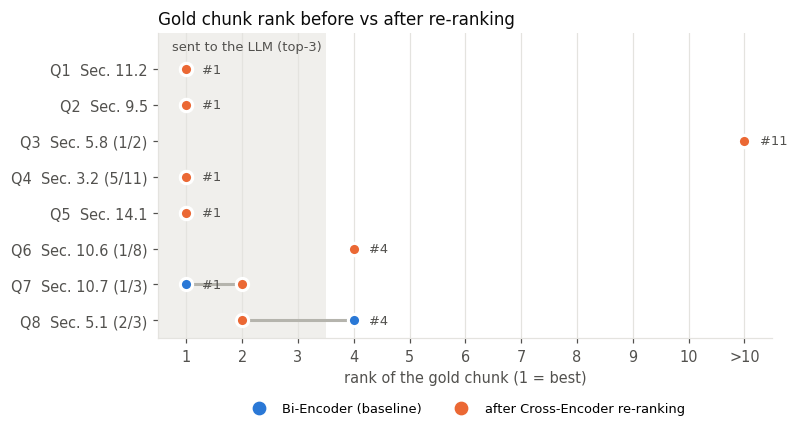

In [29]:
# Dumbbell chart: where the gold chunk sits before (blue) and after (orange) re-ranking.
fig, ax = plt.subplots(figsize=(7.2, 3.6))
ax.axvspan(0.5, TOP_N + 0.5, color="#f0efec", zorder=0, lw=0)
ax.text(TOP_N + 0.42, -0.62, "sent to the LLM (top-3)", ha="right", va="center", color=INK_2, fontsize=8.5)
for y, r in enumerate(stress_results):
    b, a = r["base_rank"] or TOP_K + 1, r["rr_rank"] or TOP_K + 1   # "not in top-10" drawn at 11
    ax.plot([b, a], [y, y], color="#b5b4ad", lw=2, zorder=1, solid_capstyle="round")
    ax.scatter([b], [y], s=64, color=C_BASE, zorder=3, edgecolor="white", linewidth=2)
    ax.scatter([a], [y], s=64, color=C_RERANK, zorder=3, edgecolor="white", linewidth=2)
    ax.text(b + 0.28, y, f"#{b}", va="center", color=INK_2, fontsize=8.5)
ax.set_yticks(range(len(stress_results)))
ax.set_yticklabels([f"{r['id']}  {r['gold_refs'][0]}" for r in stress_results])
ax.invert_yaxis()
ax.set_xlim(0.5, TOP_K + 1.5)
ax.set_ylim(len(stress_results) - 0.5, -1.0)
ax.set_xticks(range(1, TOP_K + 2))
ax.set_xticklabels([str(i) for i in range(1, TOP_K + 1)] + [">10"])
ax.set_xlabel("rank of the gold chunk (1 = best)")
ax.grid(axis="y", visible=False)
ax.scatter([], [], s=64, color=C_BASE, label="Bi-Encoder (baseline)")
ax.scatter([], [], s=64, color=C_RERANK, label="after Cross-Encoder re-ranking")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.17), ncol=2, fontsize=8.5)
ax.set_title("Gold chunk rank before vs after re-ranking", loc="left")
fig.savefig(FIG_DIR / "rank_shift.png")
plt.show()

In [30]:
# Which stress queries moved up / down after re-ranking?
n_s = len(stress_results)
in1 = sum((r["base_rank"] or 99) <= TOP_N for r in stress_results)
in2 = sum((r["rr_rank"] or 99) <= TOP_N for r in stress_results)
up = [r["id"] for r in stress_results if (r["rr_rank"] or 99) < (r["base_rank"] or 99)]
down = [r["id"] for r in stress_results if (r["rr_rank"] or 99) > (r["base_rank"] or 99)]
print(f"Gold chunk inside the LLM context (top-{TOP_N}): baseline {in1}/{n_s}, re-ranked {in2}/{n_s}.")
print(f"Gold chunk moved up after re-ranking: {', '.join(up) or 'none'} | moved down: {', '.join(down) or 'none'}")
print("Next: read Answer 1 vs Answer 2 above and fill the two verdict columns of `shift_df`.")

Gold chunk inside the LLM context (top-3): baseline 5/8, re-ranked 6/8.
Gold chunk moved up after re-ranking: Q8 | moved down: Q7
Next: read Answer 1 vs Answer 2 above and fill the two verdict columns of `shift_df`.


## 9. Where re-ranking does *not* help

In [31]:
LIMIT_QUERIES = [
    {"id": "L1", "category": "Re-ranker demotes the gold chunk (negation)",
     "query": "When does a seller who finances a sale not have to be treated as a loan originator?",
     "gold": ["under the first special exclusion", "Under the second special exclusion"],
     "expected": "Sec. 3.5: a seller financer is not a loan originator under either special exclusion: (1) a natural person, "
                 "estate or trust financing only one property in 12 months that it owned and did not build, with no negative "
                 "amortization and a fixed rate or an adjustable rate that resets after five or more years; or (2) any seller "
                 "financing entity financing three or fewer properties in 12 months, owned and not built, fully amortizing, same "
                 "rate rule, plus a good-faith ability-to-repay finding."},
    {"id": "L2", "category": "Recall ceiling (gold not in top-10)",
     "query": "Are time-share plans exempt from the compensation provisions?",
     "gold": ["do not apply to: - Open-end credit plans including HELOCs - Time-share plans"],
     "expected": "Sec. 2.4: no - the compensation, qualification, identification and policies-and-procedures provisions do not "
                 "apply to open-end credit plans (including HELOCs) or time-share plans. Trap: many other passages mention time- "
                 "share plans only as an exception to the arbitration, waiver and credit-insurance prohibitions."},
]
limit_results = []
for sq in LIMIT_QUERIES:
    gold = gold_ids(sq["gold"])
    res = run_both_pipelines(sq["query"])
    res.update(sq)
    res["gold_ids"], res["gold_refs"] = sorted(gold), sorted({chunk_df.ref[g] for g in gold})
    res["base_rank"], res["rr_rank"] = rank_of(res["base_ids"], gold), rank_of(res["rr_ids"], gold)
    res["full_bi_rank"] = full_bi_rank(sq["query"], gold)
    res["table"] = rank_table(res, gold)
    limit_results.append(res)

show_stress(limit_results[0])

### L1 - Re-ranker demotes the gold chunk (negation)
**Query:** When does a seller who finances a sale not have to be treated as a loan originator?  
**Gold chunk:** Sec. 3.5 (2/5), Sec. 3.5 (4/5) - **Rank shift: #1 -> #1**  
**Correct answer (from the regulation):** Sec. 3.5: a seller financer is not a loan originator under either special exclusion: (1) a natural person, estate or trust financing only one property in 12 months that it owned and did not build, with no negative amortization and a fixed rate or an adjustable rate that resets after five or more years; or (2) any seller financing entity financing three or fewer properties in 12 months, owned and not built, fully amortizing, same rate rule, plus a good-faith ability-to-repay finding.

,chunk,page,cosine,CE score,rerank rank,shift,gold,-> P1 LLM,-> P2 LLM
base rank,,,,,,,,,
1,Sec. 3.5 (2/5),26,0.722,6.11,2,-1,GOLD,x,x
2,Sec. 3.5 (1/5),26,0.708,5.58,3,-1,,x,x
3,Sec. 3.5 (4/5),27,0.703,6.54,1,2,GOLD,x,x
4,Sec. 3.4 (2/2),25,0.677,0.46,8,-4,,,
5,Sec. 2.2 (1/5),16,0.671,-0.71,9,-4,,,
6,Sec. 2.2 (2/5),17,0.669,2.44,5,1,,,
7,Sec. 3.4 (1/2),25,0.646,1.64,6,1,,,
8,Sec. 3.2 (3/11),21-22,0.638,1.22,7,1,,,
9,Sec. 3.5 (5/5),27,0.637,3.67,4,5,,,


Answer 1 (baseline top-3: ['Sec. 3.5 (2/5)', 'Sec. 3.5 (1/5)', 'Sec. 3.5 (4/5)'])
A seller who finances a sale is not required to be treated as a loan originator if they meet the following criteria [Sec. 3.5 (2/5)]: They provide seller financing for only one property in any 12-month period, own the property securing the financing, did not construct or act as a contractor for the construction of a residence on the property in their ordinary course of business, and the financing is fully amortizing with a fixed rate or an adjustable rate that resets after five or more years.

Answer 2 (re-ranked top-3: ['Sec. 3.5 (4/5)', 'Sec. 3.5 (2/5)', 'Sec. 3.5 (1/5)'])
A seller who finances a sale is not required to be treated as a loan originator if they meet any of the following conditions:

- They provide seller financing for only one property in any 12-month period.
- They own the property securing the financing.
- They did not construct, or act as a contractor for the construction of, a residen

In [32]:
show_stress(limit_results[1])
print(f"\nBi-Encoder rank of the gold chunk among all {len(chunks)} chunks: #{limit_results[1]['full_bi_rank']}")

### L2 - Recall ceiling (gold not in top-10)
**Query:** Are time-share plans exempt from the compensation provisions?  
**Gold chunk:** Sec. 2.4 (1/2) - **Rank shift: not in top-10 -> not in top-10**  
**Correct answer (from the regulation):** Sec. 2.4: no - the compensation, qualification, identification and policies-and-procedures provisions do not apply to open-end credit plans (including HELOCs) or time-share plans. Trap: many other passages mention time- share plans only as an exception to the arbitration, waiver and credit-insurance prohibitions.

,chunk,page,cosine,CE score,rerank rank,shift,gold,-> P1 LLM,-> P2 LLM
base rank,,,,,,,,,
1,Sec. 8.3 (2/4),49,0.551,-4.66,8,-7,,x,
2,Sec. 8.4 (3/3),51,0.547,-4.43,7,-5,,x,
3,Sec. 8.6 (2/2),52,0.521,-5.55,9,-6,,x,
4,Sec. 8.7 (1/12),52-53,0.514,-2.82,5,-1,,,
5,Sec. 8.4 (2/3),50-51,0.499,-3.78,6,-1,,,
6,Sec. 8.3 (4/4),50,0.490,-2.77,4,2,,,
7,Sec. 8.3 (3/4),49,0.488,-0.51,1,6,,,x
8,Sec. 6.1,41,0.486,-2.22,3,5,,,x
9,Sec. 8.5,51-52,0.482,-1.89,2,7,,,x


Answer 1 (baseline top-3: ['Sec. 8.3 (2/4)', 'Sec. 8.4 (3/3)', 'Sec. 8.6 (2/2)'])
The provided context does not answer this question.

Answer 2 (re-ranked top-3: ['Sec. 8.3 (3/4)', 'Sec. 8.5', 'Sec. 6.1'])
The provided context does not answer this question.

Bi-Encoder rank of the gold chunk among all 198 chunks: #64


**Observations on the counter-examples** (generated from the measured ranks - they say whether each hypothesis held on this run)

In [33]:
# Observations on the counter-examples (generated from the measured ranks)
l1, l2 = limit_results
fmt = lambda r: f"#{r}" if r else "not in top-10"
print(f"L1 ({l1['category']}): gold {', '.join(l1['gold_refs'])}; baseline {fmt(l1['base_rank'])} -> re-ranked {fmt(l1['rr_rank'])}.")
if l1["base_rank"] and (l1["rr_rank"] or 99) > l1["base_rank"]:
    print("   -> the Cross-Encoder DEMOTED the gold chunk; compare Answer 1 and Answer 2 above.")
else:
    print("   -> the expected demotion did not occur for this query; if you want a counter-example here, try another abstract negated question.")
print(f"L2 ({l2['category']}): gold {', '.join(l2['gold_refs'])}; Bi-Encoder rank among all {len(chunks)} chunks: #{l2['full_bi_rank']}; "
      f"in the top-{TOP_K}: {l2['base_rank'] is not None}.")
if l2["base_rank"] is None:
    print("   -> recall ceiling confirmed: re-ranking only re-orders the top-10, so it cannot recover a chunk Stage 1 missed.")
else:
    print("   -> the gold chunk IS in the top-10 here, so this query shows no recall ceiling; swap in a query whose gold chunk ranks below #10.")
print("Section 12 shows where the Cross-Encoder would rank the L2 gold chunk if it scored every chunk.")

L1 (Re-ranker demotes the gold chunk (negation)): gold Sec. 3.5 (2/5), Sec. 3.5 (4/5); baseline #1 -> re-ranked #1.
   -> the expected demotion did not occur for this query; if you want a counter-example here, try another abstract negated question.
L2 (Recall ceiling (gold not in top-10)): gold Sec. 2.4 (1/2); Bi-Encoder rank among all 198 chunks: #64; in the top-10: False.
   -> recall ceiling confirmed: re-ranking only re-orders the top-10, so it cannot recover a chunk Stage 1 missed.
Section 12 shows where the Cross-Encoder would rank the L2 gold chunk if it scored every chunk.


## 10. Retrieval quality on a larger labelled query set

In [34]:
EXTRA_QUERIES = [
    ("What actions make someone a loan originator?", ["for compensation or other monetary gain performs loan origination activities"]),
    ("Is a loan processor who just assembles application packages a loan originator?", ["Perform loan-processing activities, such as compiling and assembling credit application packages"]),
    ("Can an employee who only hands a credit application to a consumer be a loan originator?", ["provides a credit application from the entity for which the person works"]),
    ("When is an employee of a manufactured home retailer not a loan originator?", ["does not receive compensation or gain for engaging in"]),
    ("How many properties can a seller finance in a year without becoming a loan originator?", ["finance the sales of three or fewer properties in any 12-month period"]),
    ("What limits apply to rate increases on seller-financed adjustable-rate loans?", ["An annual rate increase of 2 percentage points or less is reasonable"]),
    ("Do HUD-approved housing counselors count as loan originators?", ["your compensation is not contingent on referrals or on engaging in additional loan origination activities"]),
    ("What happens if a broker marks up the fee for a credit report?", ["a practice known as"]),
    ("Is an extra commission for selling title insurance to the borrower allowed for an individual originator?", ["This extra commission is compensation, regardless of how it is labeled"]),
    ("Are dividends paid to the owners of a brokerage firm treated as compensation?", ["Bona fide returns or dividends must be paid based on documented ownership or equity interests"]),
    ("Can a loan officer be paid more when the loan has a prepayment penalty?", ["receiving higher compensation based on whether the loan contract contains a prepayment penalty"]),
    ("Can a creditor pay a loan originator a percentage of the loan amount?", ["is not a transaction term if the loan originator compensation is based on a fixed percentage of the amount of credit extended"]),
    ("Is holding a loan in portfolio versus selling it a proxy for a loan term?", ["Compensation based on whether a loan is held in portfolio or sold into the secondary market could be compensation based on a proxy"]),
    ("What two conditions make a factor a proxy for a transaction term?", ["The factor consistently varies with a transaction term or terms over a significant number of transactions"]),
    ("Which compensation methods are treated as safe harbors?", ["recognizes seven permissible compensation methods"]),
    ("Can a creditor raise what it pays per loan in the middle of the year?", ["you may periodically revise your compensation arrangement with the loan originator"]),
    ("Can loan originators pool and share their commissions?", ["you may not pool and share compensation with other loan originators who originate transactions with different terms"]),
    ("Can an employer contribute mortgage profits to a 401(k) for a loan originator?", ["You may structure tax-advantaged deferred compensation that is based on mortgage-related profits in two ways"]),
    ("What revenue counts as profits from a mortgage-related business?", ["Origination fees you or your affiliate collected"]),
    ("How do I work out an originator's total compensation for the 10 percent limit?", ["wages and tips reportable for Medicare tax purposes in box 5 on IRS Form W-2"]),
    ("Can an originator who closed only a handful of loans get a profit-sharing bonus?", ["may be compensated under a non-deferred profits-based compensation plan if you meet two tests"]),
    ("What if a loan originator relied on an inaccurate profit statement from the employer?", ["you relied in good faith on an accounting or statement provided by the person who determined your compensation"]),
    ("If the home seller agrees to cover some closing costs, is the originator's fee treated as paid by the consumer?", ["that is considered direct compensation from the consumer"]),
    ("Can an origination fee be paid partly by the consumer and partly by the lender?", ["must be paid entirely by the consumer or entirely out of funds paid by the creditor"]),
    ("Whose licenses must a loan originator organization check?", ["Individual loan originators who work for you include employees and independent contractors who operate pursuant to a brokerage agreement"]),
    ("What background information must be collected on loan officers who are not licensed?", ["Information from the NMLSR on administrative, civil, or criminal findings"]),
    ("Does a pardoned conviction disqualify a loan originator?", ["Expunged convictions and pardoned convictions"]),
    ("Do I have to look at credit scores when judging financial responsibility?", ["Your procedures do not have to include a review of a credit score"]),
    ("How often does an employer have to train its loan originators?", ["sufficient in frequency, timing, duration, and content"]),
    ("Which loan documents must show the originator's NMLSR ID?", ["The loan documents that must contain the name and NMLSR ID are the"]),
    ("Can credit insurance premiums that are paid monthly be financed?", ["This prohibition does not apply to credit insurance when the premiums or fees are calculated and paid in full on a monthly basis"]),
    ("Which banks must have written compliance policies for loan originators?", ["must establish and maintain written policies and procedures reasonably designed to ensure and monitor your compliance"]),
    ("Can a mortgage contract stop the borrower from suing under federal law?", ["may not bar a consumer from bringing a claim in court asserting a violation of any federal law"]),
]
eval_set = [(r["query"], r["gold"]) for r in STRESS_QUERIES + LIMIT_QUERIES] + EXTRA_QUERIES
print(len(eval_set), "labelled queries")

eval_rows = []
for q, g in eval_set:
    gold = gold_ids(g)
    assert gold, f"gold phrase not found for: {q}"
    res = run_both_pipelines(q, generate=False)
    eval_rows.append({"query": q, "gold": ", ".join(sorted({chunk_df.ref[i] for i in gold})),
                      "baseline rank": rank_of(res["base_ids"], gold), "re-ranked rank": rank_of(res["rr_ids"], gold)})
eval_df = pd.DataFrame(eval_rows)
eval_df.to_csv(RESULTS_DIR / "eval_ranks.csv", index=False)


def metrics(col):
    r = eval_df[col]
    return {"Hit@1": (r == 1).mean(), "Hit@3 (gold reaches LLM)": (r <= 3).mean(),
            "MRR@10": np.mean([1 / x if pd.notna(x) else 0.0 for x in r]),
            "Recall@10": r.notna().mean()}


metrics_df = pd.DataFrame({"Pipeline 1 (Bi-Encoder)": metrics("baseline rank"),
                           "Pipeline 2 (+ Cross-Encoder)": metrics("re-ranked rank")}).T.round(3)
metrics_df.to_csv(RESULTS_DIR / "eval_metrics.csv")
metrics_df

43 labelled queries


,Hit@1,Hit@3 (gold reaches LLM),MRR@10,Recall@10
Pipeline 1 (Bi-Encoder),0.419,0.674,0.565,0.837
Pipeline 2 (+ Cross-Encoder),0.651,0.767,0.722,0.837


In [35]:
in_top10 = eval_df.dropna(subset=["baseline rank"])
better = (in_top10["re-ranked rank"] < in_top10["baseline rank"]).sum()
worse = (in_top10["re-ranked rank"] > in_top10["baseline rank"]).sum()
same = (in_top10["re-ranked rank"] == in_top10["baseline rank"]).sum()
rescued = ((in_top10["baseline rank"] > 3) & (in_top10["re-ranked rank"] <= 3)).sum()
lost = ((in_top10["baseline rank"] <= 3) & (in_top10["re-ranked rank"] > 3)).sum()
print(f"Gold in top-10 for {len(in_top10)}/{len(eval_df)} queries. Among those, re-ranking moved the gold chunk "
      f"up in {better}, down in {worse}, unchanged in {same}.")
print(f"Pushed INTO the LLM context (rank>3 -> <=3): {rescued} | pushed OUT of it (<=3 -> >3): {lost}")
eval_df.sort_values("baseline rank", na_position="last")

Gold in top-10 for 36/43 queries. Among those, re-ranking moved the gold chunk up in 13, down in 4, unchanged in 19.
Pushed INTO the LLM context (rank>3 -> <=3): 6 | pushed OUT of it (<=3 -> >3): 2


,query,gold,baseline rank,re-ranked rank
0,How long do I need to keep my loan originator compensation records?,Sec. 11.2,1.0,1.0
1,"If the borrower pays the brokerage firm directly, can the firm still pay its loan officer a commission on that loan?",Sec. 9.5,1.0,1.0
3,Is a licensed real estate agent a loan originator if they only help with the home sale?,Sec. 3.2 (5/11),1.0,1.0
4,Can a lender require borrowers to settle disputes through arbitration?,Sec. 14.1,1.0,1.0
6,Do independent mortgage brokers have to complete our training program?,Sec. 10.7 (1/3),1.0,2.0
8,When does a seller who finances a sale not have to be treated as a loan originator?,"Sec. 3.5 (2/5), Sec. 3.5 (4/5)",1.0,1.0
15,What limits apply to rate increases on seller-financed adjustable-rate loans?,Sec. 3.5 (3/5),1.0,1.0
12,Can an employee who only hands a credit application to a consumer be a loan originator?,Sec. 3.2 (3/11),1.0,2.0
33,Can an origination fee be paid partly by the consumer and partly by the lender?,Sec. 9.4 (1/3),1.0,1.0
38,How often does an employer have to train its loan originators?,Sec. 10.7 (2/3),1.0,1.0


## 11. Latency profiling

We time each stage separately with `time.perf_counter()` on CPU, after warm-up:

* **Bi-Encoder retrieval** = embed the query + FAISS search (shared by both pipelines);
* **Cross-Encoder re-ranking** = score 10 pairs + sort (Pipeline 2 only);
* **LLM generation** = measured during the stress tests above (10 queries x 2 pipelines = 20 generations).

Retrieval stages are repeated 5 times over every labelled query.

In [36]:
REPEATS = 5  # x len(eval_set) queries
for q, _ in eval_set[:3]:          # warm-up (first calls allocate buffers / JIT kernels)
    run_both_pipelines(q, generate=False)

lat = []
for _ in range(REPEATS):
    for q, _ in eval_set:
        r = run_both_pipelines(q, generate=False)
        lat.append({"bi_ms": r["retrieval_ms"], "ce_ms": r["rerank_ms"]})
lat = pd.DataFrame(lat)
lat["p1_retrieval_ms"] = lat["bi_ms"]
lat["p2_retrieval_ms"] = lat["bi_ms"] + lat["ce_ms"]

all_runs = stress_results + limit_results
gen = pd.DataFrame([{"pipeline": p, "gen_s": r[p]["gen_s"], "prompt_tokens": r[p]["prompt_tokens"],
                     "new_tokens": r[p]["new_tokens"]} for r in all_runs for p in ("p1", "p2")])


def summarise(series_ms):
    return {"mean (ms)": series_ms.mean(), "median (ms)": series_ms.median(), "p95 (ms)": series_ms.quantile(0.95)}


stage_df = pd.DataFrame({
    "Bi-Encoder retrieval (embed + FAISS top-10)": summarise(lat["bi_ms"]),
    "Cross-Encoder re-rank (10 pairs)": summarise(lat["ce_ms"]),
    "Pipeline 1 retrieval total": summarise(lat["p1_retrieval_ms"]),
    "Pipeline 2 retrieval total": summarise(lat["p2_retrieval_ms"]),
    "LLM generation - Pipeline 1": summarise(gen[gen.pipeline == "p1"].gen_s * 1e3),
    "LLM generation - Pipeline 2": summarise(gen[gen.pipeline == "p2"].gen_s * 1e3),
}).T.round(1)
stage_df.to_csv(RESULTS_DIR / "latency_stages.csv")
stage_df

,mean (ms),median (ms),p95 (ms)
Bi-Encoder retrieval (embed + FAISS top-10),17.8,18.3,20.0
Cross-Encoder re-rank (10 pairs),292.3,288.1,340.0
Pipeline 1 retrieval total,17.8,18.3,20.0
Pipeline 2 retrieval total,310.1,306.6,357.8
LLM generation - Pipeline 1,51274.7,49580.6,72828.0
LLM generation - Pipeline 2,58510.1,60412.8,86924.1


In [37]:
p1_e2e = lat["p1_retrieval_ms"].mean() + gen[gen.pipeline == "p1"].gen_s.mean() * 1e3
p2_e2e = lat["p2_retrieval_ms"].mean() + gen[gen.pipeline == "p2"].gen_s.mean() * 1e3
e2e_df = pd.DataFrame({
    "retrieval (ms)": [lat["p1_retrieval_ms"].mean(), lat["p2_retrieval_ms"].mean()],
    "LLM generation (ms)": [gen[gen.pipeline == "p1"].gen_s.mean() * 1e3, gen[gen.pipeline == "p2"].gen_s.mean() * 1e3],
    "end-to-end (ms)": [p1_e2e, p2_e2e],
    "mean prompt tokens": [gen[gen.pipeline == "p1"].prompt_tokens.mean(), gen[gen.pipeline == "p2"].prompt_tokens.mean()],
    "mean generated tokens": [gen[gen.pipeline == "p1"].new_tokens.mean(), gen[gen.pipeline == "p2"].new_tokens.mean()],
}, index=["Pipeline 1 (baseline)", "Pipeline 2 (re-ranking)"]).round(1)
e2e_df.to_csv(RESULTS_DIR / "latency_end_to_end.csv")
ratio = lat["p2_retrieval_ms"].mean() / lat["p1_retrieval_ms"].mean()
share = lat["ce_ms"].mean() / p2_e2e * 100
print(f"Re-ranking makes retrieval {ratio:.1f}x slower, but adds only {share:.1f}% to end-to-end latency (LLM dominates).")
e2e_df

Re-ranking makes retrieval 17.5x slower, but adds only 0.5% to end-to-end latency (LLM dominates).


,retrieval (ms),LLM generation (ms),end-to-end (ms),mean prompt tokens,mean generated tokens
Pipeline 1 (baseline),17.8,51274.7,51292.5,672.0,60.8
Pipeline 2 (re-ranking),310.1,58510.1,58820.2,689.3,73.1


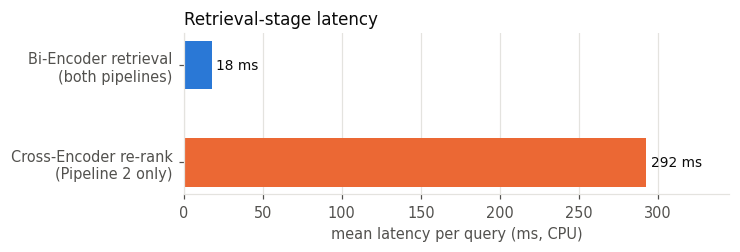

In [38]:
fig, ax = plt.subplots(figsize=(6.4, 1.9))
vals = [lat["bi_ms"].mean(), lat["ce_ms"].mean()]
labels = ["Bi-Encoder retrieval\n(both pipelines)", "Cross-Encoder re-rank\n(Pipeline 2 only)"]
bars = ax.barh(labels, vals, color=[C_BASE, C_RERANK], height=0.5)
for b, v in zip(bars, vals):
    ax.text(v + max(vals) * 0.01, b.get_y() + b.get_height() / 2, f"{v:.0f} ms", va="center", color=INK, fontsize=9)
ax.invert_yaxis()
ax.set_xlabel("mean latency per query (ms, CPU)")
ax.grid(axis="y", visible=False)
ax.set_xlim(0, max(vals) * 1.18)
ax.set_title("Retrieval-stage latency", loc="left")
fig.savefig(FIG_DIR / "latency.png")
plt.show()

## 12. Scaling: why not run the Cross-Encoder over everything?

The Bi-Encoder pays for document encoding **once, offline**; a query costs one encoder pass plus a vector search.
The Cross-Encoder has no reusable document representation: every query needs one full transformer pass **per chunk**.
We measure Cross-Encoder cost as the number of candidates grows, up to the whole corpus, and compare with Bi-Encoder search.
We also check whether "Cross-Encoder over all chunks" would at least fix the recall-ceiling example L2.

In [39]:
probe_queries = [r["query"] for r in stress_results[:3]]
ce_cost = []
for n in [n for n in (10, 25, 50, 100, 150) if n < len(chunks)] + [len(chunks)]:
    times = []
    for q in probe_queries:
        ids = list(range(n))
        t0 = time.perf_counter()
        cross_encoder.predict([(q, chunk_texts[i]) for i in ids], batch_size=32, show_progress_bar=False)
        times.append((time.perf_counter() - t0) * 1e3)
    ce_cost.append({"candidates": n, "cross-encoder ms": np.median(times)})
ce_cost = pd.DataFrame(ce_cost)
ce_cost["ms per pair"] = ce_cost["cross-encoder ms"] / ce_cost["candidates"]
per_pair_ms = ce_cost["ms per pair"].iloc[-1]
bi_ms = lat["bi_ms"].median()
ce_cost.round(2)

,candidates,cross-encoder ms,ms per pair
0,10,222.02,22.20
1,25,758.32,30.33
2,50,1511.75,30.23
3,100,3345.15,33.45
4,150,5227.94,34.85
5,198,6684.86,33.76


In [40]:
# Synthetic large corpus: FAISS exact search over 1M random 384-d unit vectors vs. a Cross-Encoder extrapolation.
rng = np.random.default_rng(SEED)
big_index = faiss.IndexFlatIP(384)
for _ in range(10):                      # add in 100k batches to keep peak memory low
    block = rng.standard_normal((100_000, 384), dtype=np.float32)
    block /= np.linalg.norm(block, axis=1, keepdims=True)
    big_index.add(block)
qv = bi_encoder.encode([probe_queries[0]], normalize_embeddings=True, convert_to_numpy=True, show_progress_bar=False).astype(np.float32)
big_index.search(qv, TOP_K)              # warm-up
t0 = time.perf_counter()
for _ in range(5):
    big_index.search(qv, TOP_K)
faiss_1m_ms = (time.perf_counter() - t0) / 5 * 1e3
del big_index, block

scale_df = pd.DataFrame({
    "corpus size": [len(chunks), 1_000_000],
    "Bi-Encoder + exact FAISS (ms/query)": [bi_ms, bi_ms - lat["bi_ms"].median() + faiss_1m_ms],
    "Cross-Encoder over everything (s/query)": [per_pair_ms * len(chunks) / 1e3, per_pair_ms * 1_000_000 / 1e3],
    "Two-stage: retrieve 10 + re-rank (ms/query)": [bi_ms + lat["ce_ms"].median(), faiss_1m_ms + bi_ms + lat["ce_ms"].median()],
}).set_index("corpus size").round(1)
scale_df.to_csv(RESULTS_DIR / "scaling.csv")
print(f"Measured FAISS exact search over 1M vectors: {faiss_1m_ms:.0f} ms; Cross-Encoder: {per_pair_ms:.2f} ms per pair")
scale_df

Measured FAISS exact search over 1M vectors: 124 ms; Cross-Encoder: 33.76 ms per pair


,Bi-Encoder + exact FAISS (ms/query),Cross-Encoder over everything (s/query),Two-stage: retrieve 10 + re-rank (ms/query)
corpus size,,,
198,18.3,6.7,306.3
1000000,123.9,33761.9,430.2


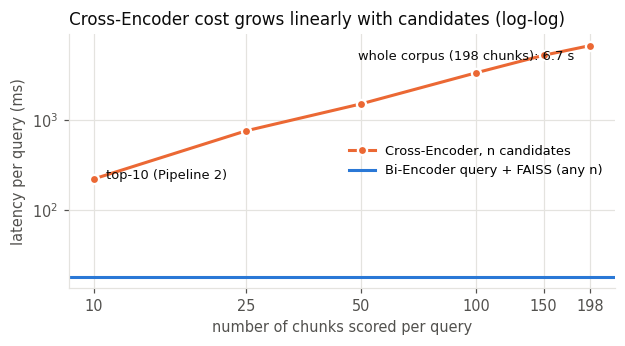

In [41]:
fig, ax = plt.subplots(figsize=(6.4, 3.0))
ax.plot(ce_cost["candidates"], ce_cost["cross-encoder ms"], color=C_RERANK, lw=2, marker="o", ms=6,
        markeredgecolor="white", markeredgewidth=1.5, label="Cross-Encoder, n candidates")
ax.axhline(bi_ms, color=C_BASE, lw=2, label="Bi-Encoder query + FAISS (any n)")
ax.annotate(f"whole corpus ({len(chunks)} chunks): {ce_cost['cross-encoder ms'].iloc[-1]/1e3:.1f} s",
            (ce_cost["candidates"].iloc[-1], ce_cost["cross-encoder ms"].iloc[-1]),
            textcoords="offset points", xytext=(-10, -3), ha="right", va="top", color=INK, fontsize=8.5)
ax.annotate("top-10 (Pipeline 2)", (10, ce_cost["cross-encoder ms"].iloc[0]),
            textcoords="offset points", xytext=(8, 2), va="center", color=INK, fontsize=8.5)
ax.set_xlabel("number of chunks scored per query")
ax.set_ylabel("latency per query (ms)")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xticks(ce_cost["candidates"], [str(n) for n in ce_cost["candidates"]])
ax.minorticks_off()
ax.legend(loc="center right", fontsize=8.5)
ax.set_title("Cross-Encoder cost grows linearly with candidates (log-log)", loc="left")
fig.savefig(FIG_DIR / "scaling.png")
plt.show()

In [42]:
# Would an "exhaustive" Cross-Encoder fix the recall-ceiling query L2?
l2 = limit_results[1]
all_scores = cross_encoder.predict([(l2["query"], t) for t in chunk_texts], batch_size=32, show_progress_bar=False)
ce_full_rank = min(int((all_scores > all_scores[g]).sum()) + 1 for g in l2["gold_ids"])
print(f"L2 '{l2['query']}'\n  gold {l2['gold_refs']}: Bi-Encoder rank over all chunks #{l2['full_bi_rank']}, "
      f"Cross-Encoder rank over all chunks #{ce_full_rank}")

L2 'Are time-share plans exempt from the compensation provisions?'
  gold ['Sec. 2.4 (1/2)']: Bi-Encoder rank over all chunks #64, Cross-Encoder rank over all chunks #1


## 13. Save outputs

In [43]:
def slim(r):
    return {"id": r["id"], "category": r["category"], "query": r["query"], "gold": r["gold_refs"],
            "expected": r["expected"], "baseline_rank": r["base_rank"], "reranked_rank": r["rr_rank"],
            "full_bi_rank": r["full_bi_rank"],
            "p1_context": [chunk_df.ref[i] for i in r["base_ids"][:TOP_N]],
            "p2_context": [chunk_df.ref[i] for i in r["rr_ids"][:TOP_N]],
            "answer_1": r["p1"]["answer"], "answer_2": r["p2"]["answer"],
            "gen_s_1": round(r["p1"]["gen_s"], 2), "gen_s_2": round(r["p2"]["gen_s"], 2)}


(RESULTS_DIR / "stress_answers.json").write_text(json.dumps([slim(r) for r in all_runs], indent=2, ensure_ascii=False))
for r in all_runs:
    r["table"].to_csv(RESULTS_DIR / f"rank_table_{r['id']}.csv")
print(sorted(p.name for p in RESULTS_DIR.iterdir()))

['eval_metrics.csv', 'eval_ranks.csv', 'latency_end_to_end.csv', 'latency_stages.csv', 'rank_table_L1.csv', 'rank_table_L2.csv', 'rank_table_Q1.csv', 'rank_table_Q2.csv', 'rank_table_Q3.csv', 'rank_table_Q4.csv', 'rank_table_Q5.csv', 'rank_table_Q6.csv', 'rank_table_Q7.csv', 'rank_table_Q8.csv', 'scaling.csv', 'stress_answers.json', 'stress_rank_shifts.csv']


## 14. Summary

The table and takeaways below are generated from the results of the cells above (nothing is hard-coded), so they always match the run.

In [44]:
from IPython.display import display, Markdown

m1, m2 = metrics_df.loc["Pipeline 1 (Bi-Encoder)"], metrics_df.loc["Pipeline 2 (+ Cross-Encoder)"]
n_s = len(stress_results)
s1 = sum((r["base_rank"] or 99) <= TOP_N for r in stress_results)
s2 = sum((r["rr_rank"] or 99) <= TOP_N for r in stress_results)
rows = [
    (f"Gold chunk reaches the LLM (Hit@3, {len(eval_df)} queries)", f"{m1['Hit@3 (gold reaches LLM)']:.1%}", f"{m2['Hit@3 (gold reaches LLM)']:.1%}"),
    ("Gold chunk at rank 1 (Hit@1)", f"{m1['Hit@1']:.1%}", f"{m2['Hit@1']:.1%}"),
    ("MRR@10", f"{m1['MRR@10']:.3f}", f"{m2['MRR@10']:.3f}"),
    ("Recall@10 (ceiling, identical by construction)", f"{m1['Recall@10']:.1%}", f"{m2['Recall@10']:.1%}"),
    (f"Stress queries: gold in top-3 (of {n_s})", f"{s1}/{n_s}", f"{s2}/{n_s}"),
    ("Retrieval latency (mean, CPU)", f"{lat['p1_retrieval_ms'].mean():.1f} ms", f"{lat['p2_retrieval_ms'].mean():.0f} ms (~{ratio:.0f}x)"),
    ("End-to-end latency incl. 3B LLM on CPU", f"{p1_e2e / 1e3:.1f} s", f"{p2_e2e / 1e3:.1f} s"),
]
display(Markdown("| | Pipeline 1 (Bi-Encoder) | Pipeline 2 (+ Cross-Encoder) |\n|---|---|---|\n"
                 + "\n".join(f"| {a} | {b} | {c} |" for a, b, c in rows)))
print(f"1. Re-ranking fixes ordering, not recall: it moved the gold chunk up in {better} of the {len(in_top10)} queries where it was in the top-10, "
      f"down in {worse}; it pushed the gold chunk into the LLM context {rescued} times and out of it {lost} times.")
print(f"2. The cost is small in a RAG system: the Cross-Encoder adds ~{lat['ce_ms'].mean() / 1e3:.2f} s per query = {share:.1f}% of end-to-end time (generation dominates).")
print(f"3. Cross-encoding everything does not scale: ~{per_pair_ms:.1f} ms per pair = ~{per_pair_ms * len(chunks) / 1e3:.0f} s per query for this one guide "
      f"and ~{per_pair_ms * 1_000_000 / 3.6e6:.1f} hours per query for 1M chunks, versus ~{faiss_1m_ms:.0f} ms for exact FAISS search over 1M vectors.")
print("4. Answer quality needs a human judge: fill the verdict columns of `shift_df` (Section 8) and quote the changed answers.")

| | Pipeline 1 (Bi-Encoder) | Pipeline 2 (+ Cross-Encoder) |
|---|---|---|
| Gold chunk reaches the LLM (Hit@3, 43 queries) | 67.4% | 76.7% |
| Gold chunk at rank 1 (Hit@1) | 41.9% | 65.1% |
| MRR@10 | 0.565 | 0.722 |
| Recall@10 (ceiling, identical by construction) | 83.7% | 83.7% |
| Stress queries: gold in top-3 (of 8) | 5/8 | 6/8 |
| Retrieval latency (mean, CPU) | 17.8 ms | 310 ms (~17x) |
| End-to-end latency incl. 3B LLM on CPU | 51.3 s | 58.8 s |

1. Re-ranking fixes ordering, not recall: it moved the gold chunk up in 13 of the 36 queries where it was in the top-10, down in 4; it pushed the gold chunk into the LLM context 6 times and out of it 2 times.
2. The cost is small in a RAG system: the Cross-Encoder adds ~0.29 s per query = 0.5% of end-to-end time (generation dominates).
3. Cross-encoding everything does not scale: ~33.8 ms per pair = ~7 s per query for this one guide and ~9.4 hours per query for 1M chunks, versus ~124 ms for exact FAISS search over 1M vectors.
4. Answer quality needs a human judge: fill the verdict columns of `shift_df` (Section 8) and quote the changed answers.
